# 4. Normalization comparison results

Consolidated replacement for `4. results_z.ipynb`, `4. results_none.ipynb`, `4. results_rk.ipynb`, and `4. results_bin.ipynb`.

It evaluates the same validation datasets for each normalization result directory and summarizes protein-level, sample/tissue-level, and high-performance-protein behavior in one concise workflow.

In [1]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import src.utils_val as uv
from src.utils_val import (
    evaluate_norm_config,
    plot_norm_summary,
    plot_norm_protein_distributions,
    build_top_protein_table,
    high_performance_counts,
    plot_norm_tissue_heatmap,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 180, "axes.titleweight": "bold"})

## 1. Configuration

The paths below preserve the original notebooks. Note that the original `bin` notebook read models from `../results_bin` but wrote plots to `../results_bin_not_full/plots`; both are kept here explicitly.

In [2]:
VAL_DATA_DIR = Path("../val_data")
OUTPUT_DIR = Path("../results_val/plots_norms_unified")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VALIDATION_DATASETS = ["iTRAQ", "LabelFree", "TMT"]

NORM_CONFIGS = [
    {"label": "zscore", "results_dir": Path("../results_val"), "plot_dir": Path("../results_val/plots_z")},
    {"label": "none", "results_dir": Path("../results_none"), "plot_dir": Path("../results_none/plots")},
    {"label": "rank", "results_dir": Path("../results_rk"), "plot_dir": Path("../results_rk/plots")},
    {"label": "bin", "results_dir": Path("../results_bin"), "plot_dir": Path("../results_bin_not_full/plots")},
]

for cfg in NORM_CONFIGS:
    cfg["plot_dir"].mkdir(parents=True, exist_ok=True)

# The original 4.* notebooks imputed missing selected RNA features as zero.
IMPUTE_MISSING_FEATURES = True

pd.DataFrame(NORM_CONFIGS)

,label,results_dir,plot_dir
0,zscore,..\results_val,..\results_val\plots_z
1,none,..\results_none,..\results_none\plots
2,rank,..\results_rk,..\results_rk\plots
3,bin,..\results_bin,..\results_bin_not_full\plots


## 2. Evaluate each normalization directory

In [3]:
norm_bundles = []
for cfg in NORM_CONFIGS:
    print("\n" + "=" * 100)
    print(f"Normalization: {cfg['label']} | models: {cfg['results_dir']}")
    print("=" * 100)
    bundle = evaluate_norm_config(
        cfg["label"],
        cfg["results_dir"],
        VAL_DATA_DIR,
        datasets=VALIDATION_DATASETS,
        impute_missing_features=IMPUTE_MISSING_FEATURES,
    )
    norm_bundles.append(bundle)

summary_df = pd.concat([b["summary"] for b in norm_bundles if len(b["summary"])], ignore_index=True) if norm_bundles else pd.DataFrame()
protein_metrics_df = pd.concat([b["protein"] for b in norm_bundles if len(b["protein"])], ignore_index=True) if norm_bundles else pd.DataFrame()
tissue_metrics_df = pd.concat([b["tissue"] for b in norm_bundles if len(b["tissue"])], ignore_index=True) if norm_bundles else pd.DataFrame()

print("Summary rows:", len(summary_df))
display(summary_df.round(4))


Normalization: zscore | models: ..\results_val

Normalization: none | models: ..\results_none
No best-model files found for none in ..\results_none

Normalization: rank | models: ..\results_rk
No best-model files found for rank in ..\results_rk

Normalization: bin | models: ..\results_bin
No best-model files found for bin in ..\results_bin
Summary rows: 3


,Normalization,Dataset,Samples,Proteins_evaluated,Mean_PCC_protein,Median_PCC_protein,Mean_Cosine_protein,Mean_MSE_protein,Median_MSE_protein,Mean_MSE_sample,Median_missing_feature_fraction
0,zscore,iTRAQ,276,1809,0.0180,0.0198,0.0123,1.0335,0.4149,1.0335,0.0025
1,zscore,LabelFree,360,1809,0.0867,0.1097,0.0889,2.6317,1.3556,2.6317,0.0025
2,zscore,TMT,1924,1809,0.1072,0.1910,0.1062,13.3526,11.4816,13.3526,0.0025


## 3. Overview plots

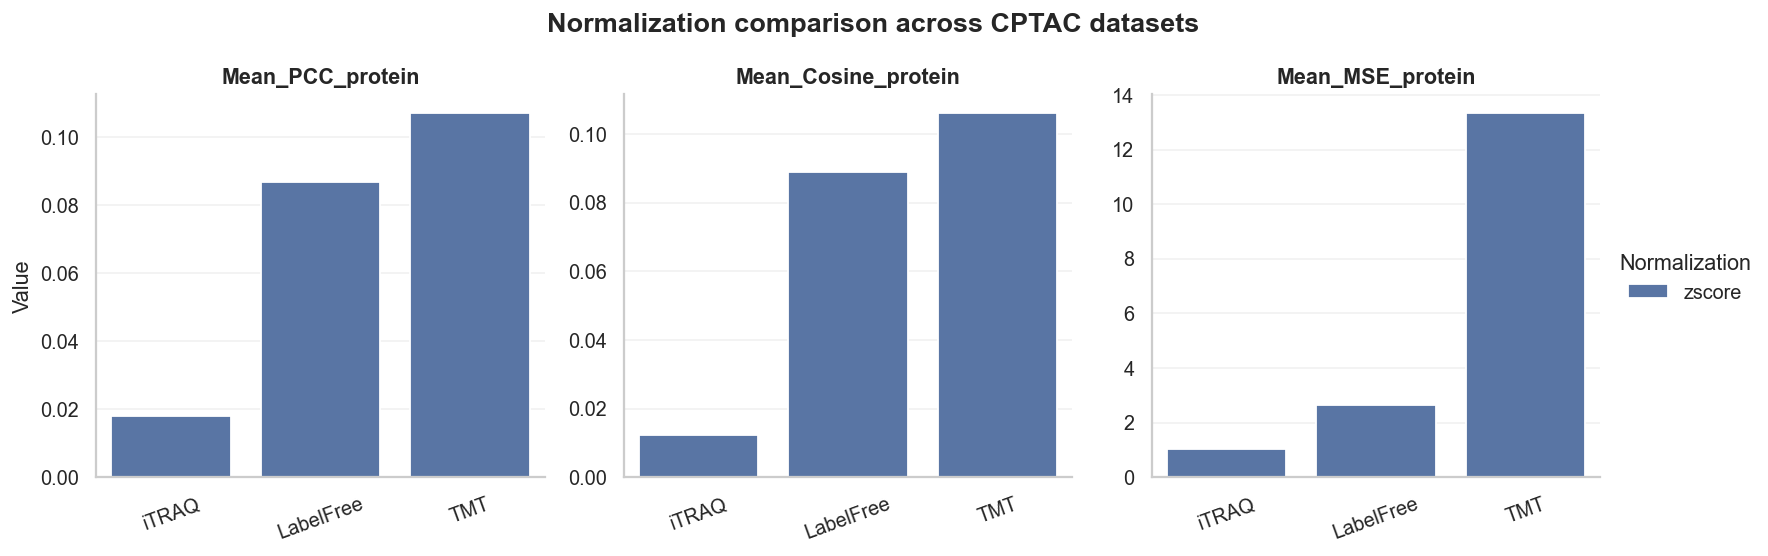

In [4]:
fig = plot_norm_summary(summary_df)
if fig is not None:
    fig.savefig(OUTPUT_DIR / "norm_summary.png", bbox_inches="tight")

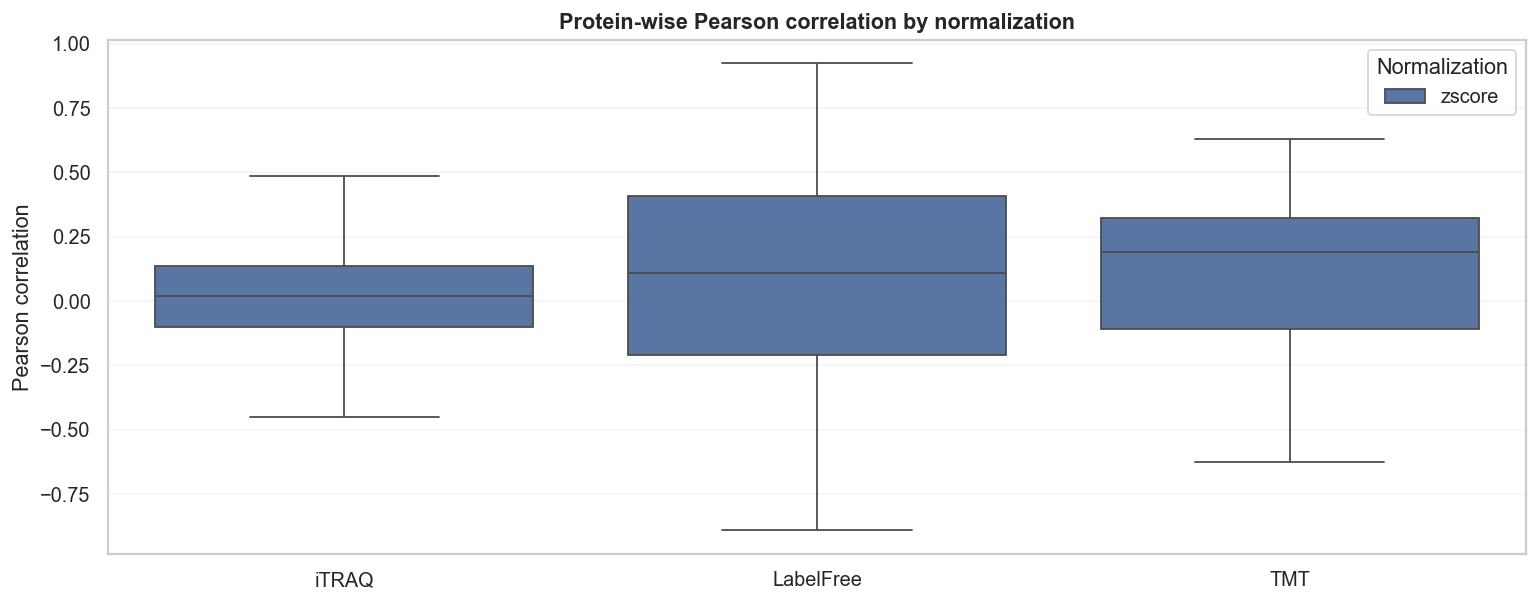

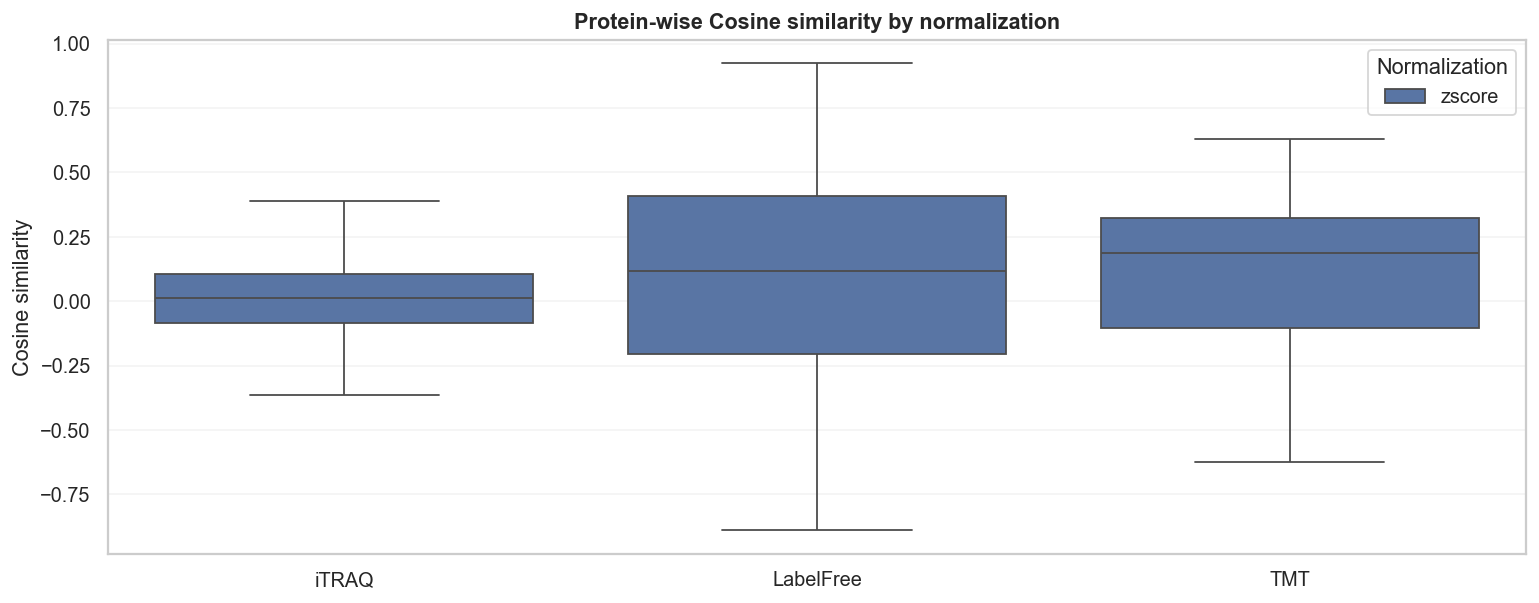

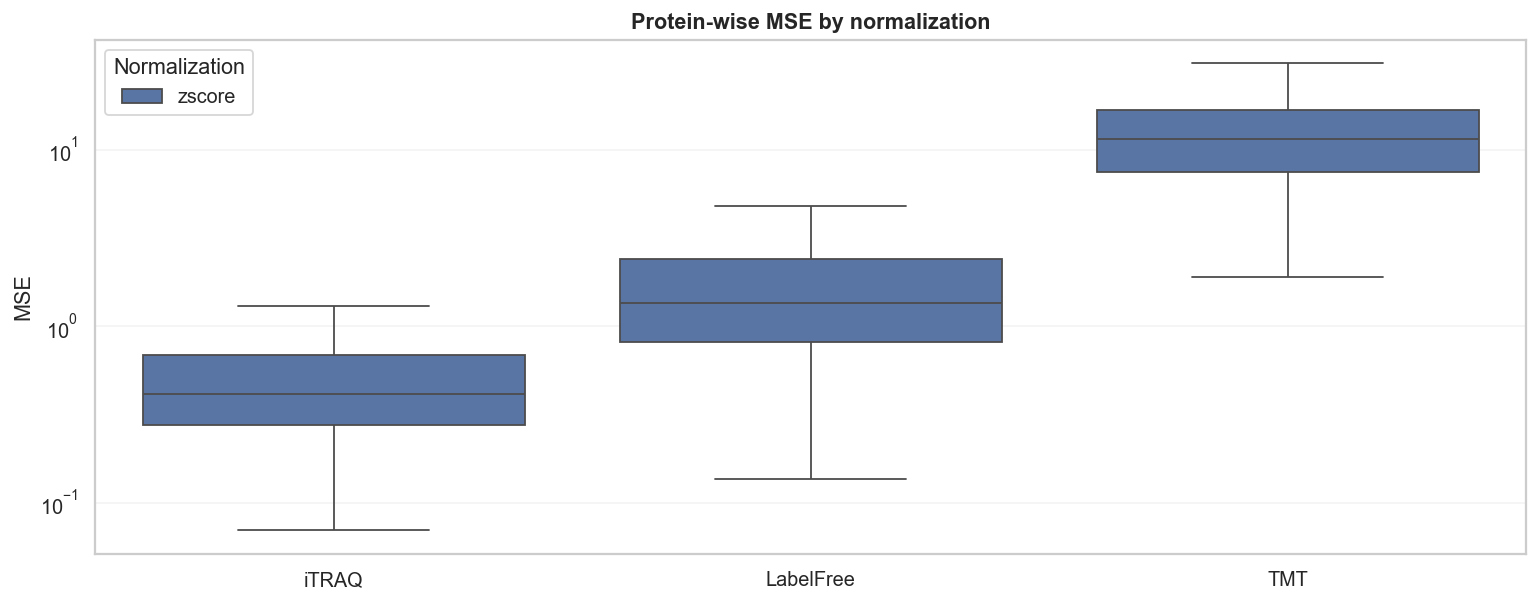

In [5]:
plot_norm_protein_distributions(protein_metrics_df)

## 4. Tissue-level comparison

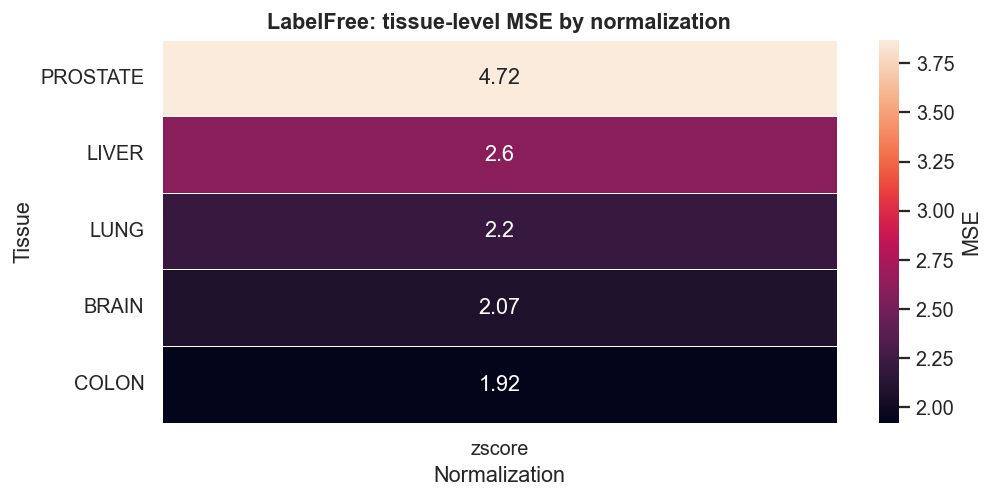

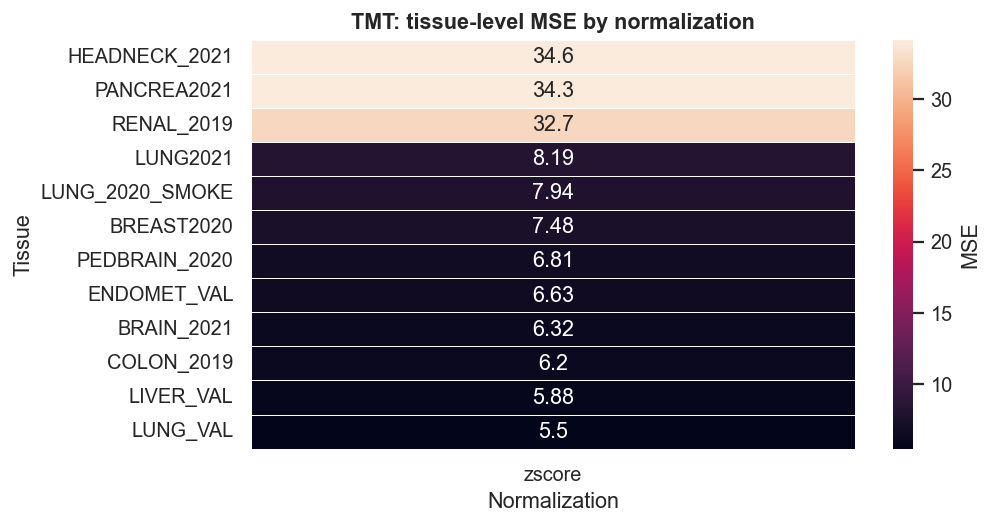

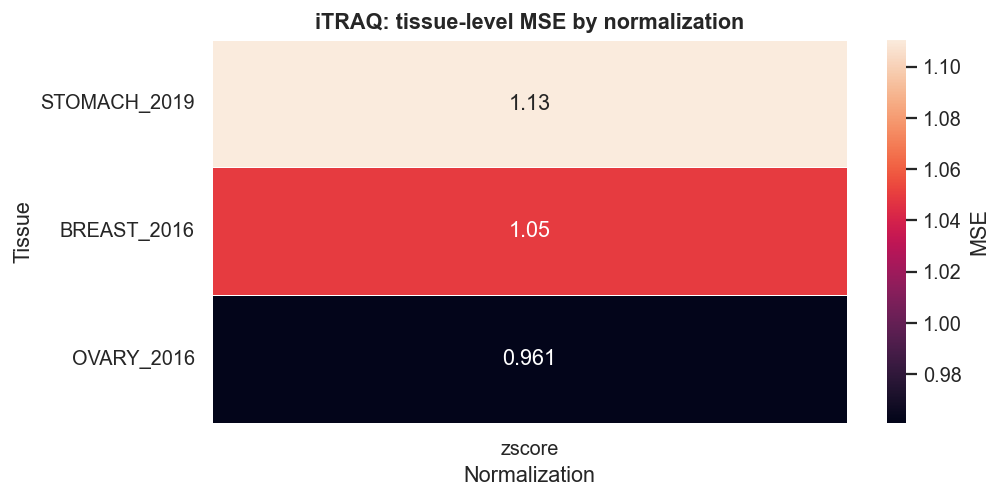

In [6]:
plot_norm_tissue_heatmap(tissue_metrics_df, metric="MSE")

## 5. High-performance proteins and top lists

In [7]:
high_perf = high_performance_counts(protein_metrics_df, threshold=0.5)
print("Proteins above 0.5 Pearson/Cosine by normalization and dataset")
display(high_perf.round(4))

top_proteins = build_top_protein_table(protein_metrics_df, top_n=20)
print("Top 20 proteins per normalization/dataset/metric")
display(top_proteins.round(4))

Proteins above 0.5 Pearson/Cosine by normalization and dataset


,Normalization,Dataset,Valid_Pearson,Pearson_gt_0.5,Pearson_share,Valid_Cosine,Cosine_gt_0.5,Cosine_share
0,zscore,LabelFree,1807,317,0.1754,1807,311,0.1721
1,zscore,TMT,1807,22,0.0122,1807,19,0.0105
2,zscore,iTRAQ,1807,6,0.0033,1807,6,0.0033


Top 20 proteins per normalization/dataset/metric


,Normalization,Dataset,Metric,Rank,Protein,Value
0,zscore,LabelFree,pearson,1,SORD,0.9243
1,zscore,LabelFree,pearson,2,UGDH,0.8931
2,zscore,LabelFree,pearson,3,RPS8,0.8928
3,zscore,LabelFree,pearson,4,GOT1,0.8867
4,zscore,LabelFree,pearson,5,AKR1C3,0.8796
...,...,...,...,...,...,...
175,zscore,iTRAQ,mse,16,EXOC4,0.1205
176,zscore,iTRAQ,mse,17,RELA,0.1212
177,zscore,iTRAQ,mse,18,STAT6,0.1216
178,zscore,iTRAQ,mse,19,CDS2,0.1237


## 6. Optional detailed dashboards

The original split notebooks generated multiple per-dataset dashboard PNGs. This consolidated notebook keeps the core plots above by default. Set `SAVE_DETAILED_TABLES = True` to export the summary, protein metrics, tissue metrics, high-performance table, and top-protein table.

In [8]:
SAVE_DETAILED_TABLES = False
if SAVE_DETAILED_TABLES:
    summary_df.to_csv(OUTPUT_DIR / "norm_summary.csv", index=False)
    protein_metrics_df.to_csv(OUTPUT_DIR / "norm_protein_metrics.csv", index=False)
    tissue_metrics_df.to_csv(OUTPUT_DIR / "norm_tissue_metrics.csv", index=False)
    high_perf.to_csv(OUTPUT_DIR / "norm_high_performance_counts.csv", index=False)
    top_proteins.to_csv(OUTPUT_DIR / "norm_top_proteins.csv", index=False)
    print("Saved tables to", OUTPUT_DIR.resolve())